In [8]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('../Data/producao-petroleo-m3.csv', sep=';', decimal=',')

pd.options.display.float_format = '{:,.2f}'.format

df.head()

,ANO,MÊS,GRANDE REGIÃO,UNIDADE DA FEDERAÇÃO,PRODUTO,LOCALIZAÇÃO,PRODUÇÃO
0,1997,JAN,REGIÃO NORTE,AMAZONAS,PETRÓLEO,TERRA,"122,200.00"
1,1997,FEV,REGIÃO NORTE,AMAZONAS,PETRÓLEO,TERRA,"124,785.00"
2,1997,MAR,REGIÃO NORTE,AMAZONAS,PETRÓLEO,TERRA,"128,177.00"
3,1997,ABR,REGIÃO NORTE,AMAZONAS,PETRÓLEO,TERRA,"124,968.00"
4,1997,MAI,REGIÃO NORTE,AMAZONAS,PETRÓLEO,TERRA,"115,710.00"


In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7920 entries, 0 to 7919
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   ANO                   7920 non-null   int64  
 1   MÊS                   7920 non-null   str    
 2   GRANDE REGIÃO         7920 non-null   str    
 3   UNIDADE DA FEDERAÇÃO  7920 non-null   str    
 4   PRODUTO               7920 non-null   str    
 5   LOCALIZAÇÃO           7920 non-null   str    
 6   PRODUÇÃO              7920 non-null   float64
dtypes: float64(1), int64(1), str(5)
memory usage: 748.3 KB


In [10]:
df.isnull().sum()

ANO                     0
MÊS                     0
GRANDE REGIÃO           0
UNIDADE DA FEDERAÇÃO    0
PRODUTO                 0
LOCALIZAÇÃO             0
PRODUÇÃO                0
dtype: int64

In [11]:
df['PRODUÇÃO'] = pd.to_numeric(df['PRODUÇÃO'], errors='coerce')

In [12]:
df['PRODUÇÃO_BARRIS'] = df['PRODUÇÃO'] * 6.28981

In [13]:
df.groupby('PRODUTO')['PRODUÇÃO_BARRIS'].sum()

PRODUTO
PETRÓLEO   23,252,836,640.81
Name: PRODUÇÃO_BARRIS, dtype: float64

In [14]:
df.head()

,ANO,MÊS,GRANDE REGIÃO,UNIDADE DA FEDERAÇÃO,PRODUTO,LOCALIZAÇÃO,PRODUÇÃO,PRODUÇÃO_BARRIS
0,1997,JAN,REGIÃO NORTE,AMAZONAS,PETRÓLEO,TERRA,"122,200.00","768,614.78"
1,1997,FEV,REGIÃO NORTE,AMAZONAS,PETRÓLEO,TERRA,"124,785.00","784,873.94"
2,1997,MAR,REGIÃO NORTE,AMAZONAS,PETRÓLEO,TERRA,"128,177.00","806,208.98"
3,1997,ABR,REGIÃO NORTE,AMAZONAS,PETRÓLEO,TERRA,"124,968.00","786,024.98"
4,1997,MAI,REGIÃO NORTE,AMAZONAS,PETRÓLEO,TERRA,"115,710.00","727,793.92"


In [15]:
producao_barris_ano = (
    df[df['ANO'].between(1997, 2025)]
    .groupby('ANO')['PRODUÇÃO_BARRIS']
    .sum()
    .reset_index()
)

producao_barris_ano

,ANO,PRODUÇÃO_BARRIS
0,1997,"305,982,330.62"
1,1998,"354,654,402.54"
2,1999,"400,772,102.35"
3,2000,"450,625,224.78"
4,2001,"471,861,304.99"
5,2002,"530,853,462.10"
6,2003,"546,079,399.83"
7,2004,"540,715,968.21"
8,2005,"596,253,444.47"
9,2006,"628,796,164.18"


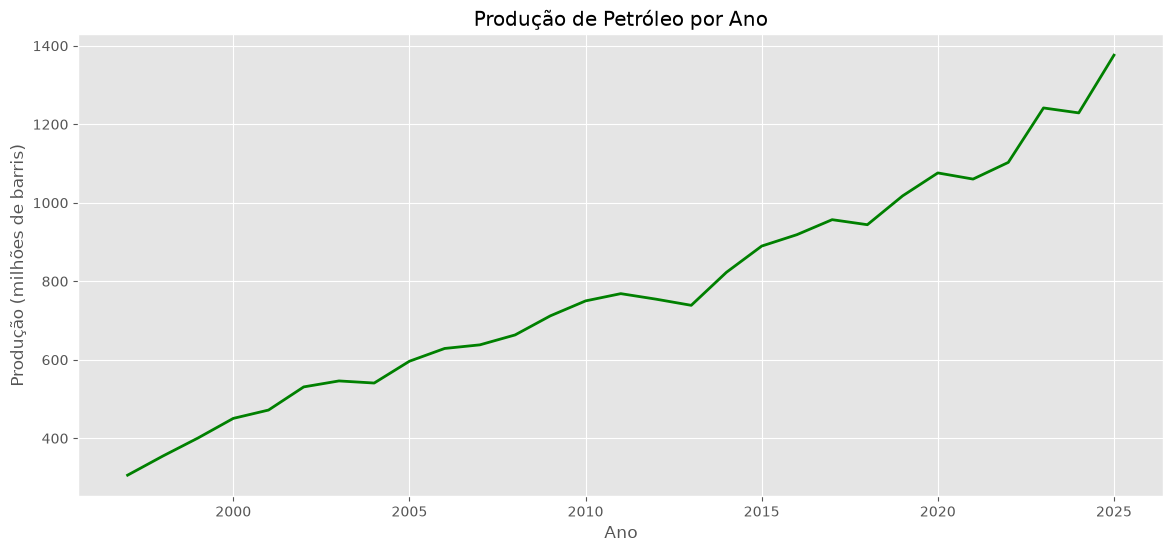

In [16]:
plt.figure(figsize=(14, 6))

plt.style.use('ggplot')

plt.plot(
    producao_barris_ano['ANO'],
    producao_barris_ano['PRODUÇÃO_BARRIS'] / 1e6,
    color='green',
    linewidth=2
)

plt.title('Produção de Petróleo por Ano')
plt.xlabel('Ano')
plt.ylabel('Produção (milhões de barris)');

In [17]:
producao_por_localizacao = (
    df.groupby('LOCALIZAÇÃO')['PRODUÇÃO_BARRIS']
    .sum()
    .reset_index()
)

producao_por_localizacao

,LOCALIZAÇÃO,PRODUÇÃO_BARRIS
0,MAR,"21,525,848,950.93"
1,TERRA,"1,726,987,689.88"


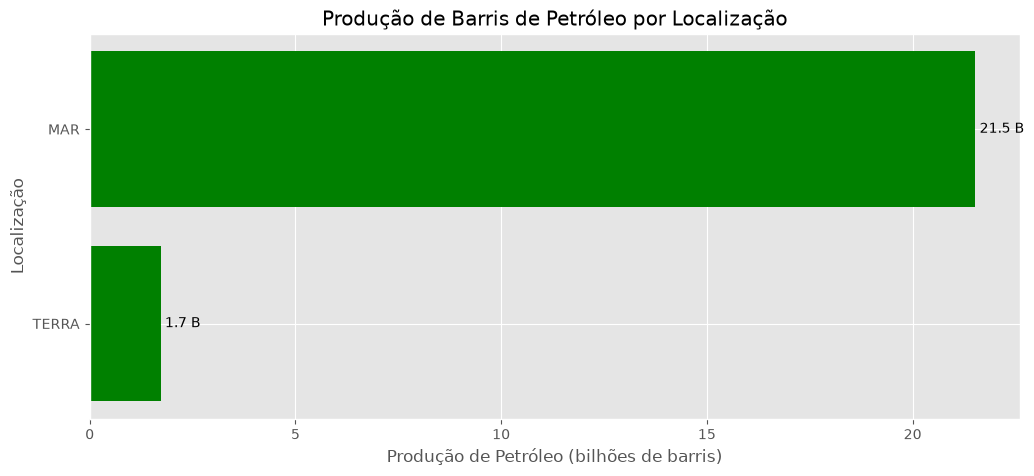

In [18]:
plt.figure(figsize=(12, 5))

barras = plt.barh(
    producao_por_localizacao['LOCALIZAÇÃO'],
    producao_por_localizacao['PRODUÇÃO_BARRIS'] / 1e9,
    color='green'
)

plt.xlabel('Produção de Petróleo (bilhões de barris)')
plt.ylabel('Localização')
plt.title('Produção de Barris de Petróleo por Localização')

plt.gca().invert_yaxis()

plt.bar_label(barras, fmt='%.1f B', padding=3);

In [19]:
producao_por_uf = (
    df[df['ANO'].between(1997, 2025)]
    .groupby('UNIDADE DA FEDERAÇÃO')['PRODUÇÃO_BARRIS']
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

producao_por_uf

,UNIDADE DA FEDERAÇÃO,PRODUÇÃO_BARRIS
0,RIO DE JANEIRO,"17,653,730,141.79"
1,ESPÍRITO SANTO,"1,829,352,634.87"
2,SÃO PAULO,"1,182,666,364.69"
3,RIO GRANDE DO NORTE,"633,531,649.55"
4,BAHIA,"400,249,628.14"
5,SERGIPE,"320,598,479.35"
6,AMAZONAS,"302,950,410.51"
7,CEARÁ,"86,935,244.98"
8,ALAGOAS,"52,733,073.58"
9,PARANÁ,"24,062,767.29"


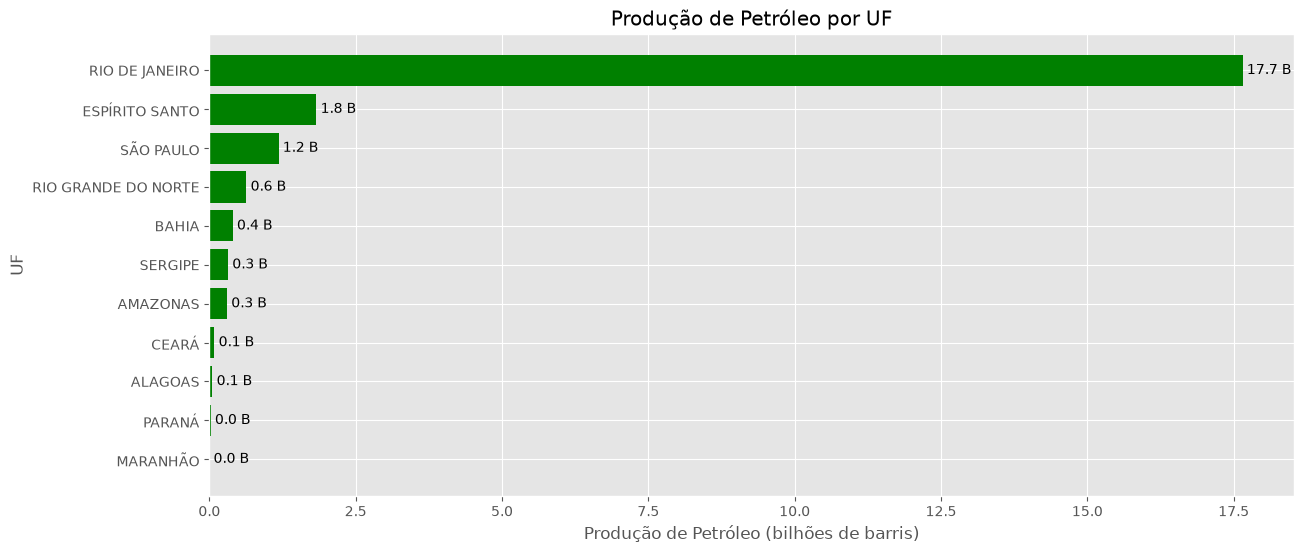

In [20]:
plt.figure(figsize=(14, 6))

barras = plt.barh(
    producao_por_uf['UNIDADE DA FEDERAÇÃO'],
    producao_por_uf['PRODUÇÃO_BARRIS'] / 1e9,
    color='green'
)

plt.title('Produção de Petróleo por UF')
plt.ylabel('UF')
plt.xlabel('Produção de Petróleo (bilhões de barris)')

plt.gca().invert_yaxis()

plt.bar_label(barras, fmt='%.1f B', padding=3);

In [21]:
producao_por_regiao = (
    df[df['ANO'].between(1997, 2025)]
    .groupby('GRANDE REGIÃO')['PRODUÇÃO_BARRIS']
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

producao_por_regiao

,GRANDE REGIÃO,PRODUÇÃO_BARRIS
0,REGIÃO SUDESTE,"20,665,749,141.35"
1,REGIÃO NORDESTE,"1,494,356,832.18"
2,REGIÃO NORTE,"302,950,410.51"
3,REGIÃO SUL,"24,062,767.29"


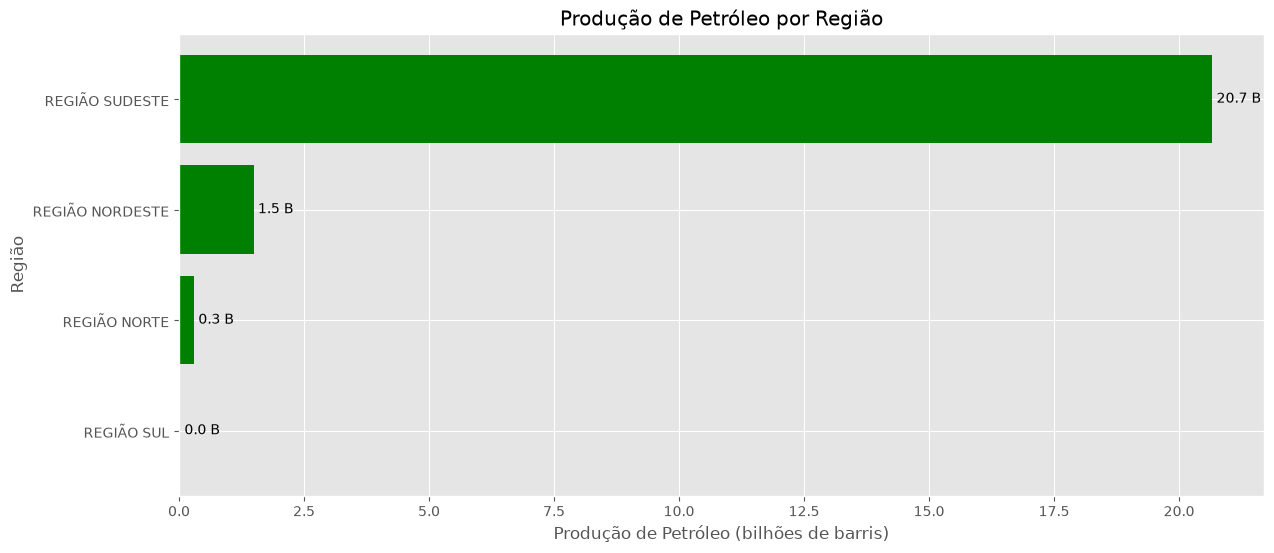

In [22]:
plt.figure(figsize=(14, 6))

barras = plt.barh(
    producao_por_regiao['GRANDE REGIÃO'],
    producao_por_regiao['PRODUÇÃO_BARRIS'] / 1e9,
    color='green'
)

plt.title('Produção de Petróleo por Região')
plt.ylabel('Região')
plt.xlabel('Produção de Petróleo (bilhões de barris)')

plt.gca().invert_yaxis()

plt.bar_label(barras, fmt='%.1f B', padding=3);

In [23]:
df.to_csv(
    'producao_petroleo.csv',
    sep=';',
    decimal=',',
    index=False
)